In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
import os
from tqdm import tqdm

In [3]:
rebecca_data_ir = pd.read_csv('processed_data_new/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])

rebecca_data_raman = pd.read_csv('processed_data_new/rebecca_data_raman_final_specy.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])

In [4]:
np.unique(rebecca_data_raman['polymer'])

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype=object)

In [5]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix_std = pd.read_csv('processed_data_new/data_ir_mix_std_rebecca.csv')
del IR_spectra_mix_std['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix_std.columns = list(np.float64(IR_spectra_mix_std.columns[:-8])) + list(IR_spectra_mix_std.columns[-8:])

IR_spectra_mix_std = (IR_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix_std.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_std_rest = IR_spectra_mix_std.loc[[x not in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std.loc[IR_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix_std = IR_spectra_mix_std.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca.csv')
Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca_specy.csv')
#notes_mix_std_rest = np.array(Raman_spectra_mix_std['comments'])
notes_mix_std = Raman_spectra_mix_std.iloc[:,-5:]

notes_mix_std = (notes_mix_std.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix_std.loc[notes_mix_std['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_std_rest[[x is np.nan for x in notes_mix_std_rest]] = ''
del Raman_spectra_mix_std['Unnamed: 0']
Raman_spectra_mix_std.columns = list(np.float64(Raman_spectra_mix_std.columns[:-7])) + list(Raman_spectra_mix_std.columns[-7:])
Raman_spectra_mix_std = (Raman_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix_std.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.sort_values('id').reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_std_rest = Raman_spectra_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
notes_mix_std_rest = notes_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

Raman_spectra_mix_std.loc[Raman_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'

#ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix_std['polymer_raman'], notes_mix_std['polymer_ir'], notes_mix_std['polymer_overall'])]
#Raman_spectra_mix_std = Raman_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)

Raman_spectra_mix_std = Raman_spectra_mix_std.query('id != 223').reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.query('id != 223').reset_index(drop=True)


In [6]:
notes_mix_std_rest.groupby('polymer_overall').count()

,comments,id,polymer_raman,polymer_ir
polymer_overall,,,,
LOW SIGNAL,1,107,107,107
MIXTURE,44,44,44,44
UNSORTED,53,54,54,54


In [7]:
notes_mix_std.groupby('polymer_overall').count()

,comments,id,polymer_raman,polymer_ir
polymer_overall,,,,
NH2SO4,3,45,45,45
NaNO3,2,13,13,13
PE,3,38,38,38
PP,0,4,4,4
PSL,5,13,13,13
sucrose,21,111,111,111


In [8]:
notes_mix_std_rest.groupby('polymer_raman').count()

,comments,id,polymer_overall,polymer_ir
polymer_raman,,,,
LOW SIGNAL,2,108,108,108
MIXTURE,43,43,43,43
NH2SO4,1,1,1,1
PE,2,2,2,2
PSL,5,5,5,5
UNSORTED,32,33,33,33
sucrose,13,13,13,13


In [9]:
notes_mix_std_rest.groupby('polymer_ir').count()

,comments,id,polymer_overall,polymer_raman
polymer_ir,,,,
LOW SIGNAL,22,128,128,128
MIXTURE,34,34,34,34
NH2SO4,6,6,6,6
PE,2,2,2,2
PP,1,1,1,1
PSL,1,1,1,1
UNSORTED,30,31,31,31
sucrose,2,2,2,2


In [10]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-8])) + list(IR_spectra_mix.columns[-8:])

IR_spectra_mix = (IR_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_rest = IR_spectra_mix.loc[[x not in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix = IR_spectra_mix.loc[[x in poly_list for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix.loc[IR_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix = IR_spectra_mix.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca.csv')
Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_specy.csv')
#notes_mix_rest = np.array(Raman_spectra_mix['comments'])
notes_mix = Raman_spectra_mix.iloc[:,-5:]

notes_mix = (notes_mix.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix.loc[notes_mix['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix.loc[notes_mix['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix.loc[notes_mix['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_rest[[x is np.nan for x in notes_mix_rest]] = ''
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-7])) + list(Raman_spectra_mix.columns[-7:])
Raman_spectra_mix = (Raman_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.sort_values('id').reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_rest = Raman_spectra_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
notes_mix_rest = notes_mix.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

Raman_spectra_mix.loc[Raman_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'

#ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) for x, y, z in zip(notes_mix['polymer_raman'], notes_mix['polymer_ir'], notes_mix['polymer_overall'])]
#Raman_spectra_mix = Raman_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)


In [11]:
IR_spectra_mix_rest.query('id == 136 or id == 217')

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
125,-0.458293,-0.381986,-0.291597,-0.071482,0.102961,0.042253,-0.242010,-0.278758,-0.181451,-0.101000,...,-0.754732,-0.923426,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,136,no_background
128,-0.596220,-0.590548,-0.590095,-0.600481,-0.602661,-0.594409,-0.589836,-0.580672,-0.558146,-0.550383,...,1.858261,1.505509,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,217,no_background


In [12]:
def envelop(score_list, label_ir, score_example, alphas, N_sim=1, quant_prop=.2, cal_prop=.8, seed_init=0):
    env_list = defaultdict(list)
    ps_list = defaultdict(list)
    ps_ir_list = defaultdict(list)
    ps_raman_list = defaultdict(list)
    q_ir_list = defaultdict(list)
    q_raman_list = defaultdict(list)
    cal_idx_list = defaultdict(list)
        
    for alpha in tqdm(alphas):
        set_size = defaultdict(list)
        set_size_all = defaultdict(list)
        zero_sets = defaultdict(list)
        cov = defaultdict(list)
        cov_cal = defaultdict(list)
        set_size_by_label_hqi = defaultdict(list)
        K = 2
        U_list = gen_u(K, n_th=400, seed=0)
        seed = seed_init
        for l in range(N_sim):
            seed = seed + l

            #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
            #top_views = np.array(acc_list)
            quant_smx_list = []
            rest_smx_list = []
            cal_smx_list = []
            val_smx_list = []


            for i in range(K):

                quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=quant_prop, seed=seed)
                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=cal_prop, seed=seed)
                

                quant_smx_list.append(quant_smx)
                rest_smx_list.append(rest_smx)
                cal_smx_list.append(cal_smx)
                val_smx_list.append(val_smx)

            n = cal_labels.shape[0]
            #n = quant_labels.shape[0]

            prediction_sets, U_quant_env = mvcp_2(quant_smx_list,
                                                             quant_labels,
                                                             cal_smx_list, #quant_smx_list,
                                                             cal_labels, #quant_labels,
                                                             score_example,#val_smx_list, #rest_smx_list, 
                                                             alpha, 
                                                             val_labels=None, #rest_labels,
                                                             U=U_list[0])

            
            s_u = rest_smx_list[0]

            cal_ir_smx, val_ir_smx, cal_ir_labels, val_ir_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            n = cal_ir_smx.shape[0]
            prediction_sets_ir, qhat_ir = conform_prediction(cal_ir_smx, score_example[0], cal_ir_labels, n, alpha, val_labels=None, cond=0)

            s_u = rest_smx_list[1]

            cal_raman_smx, val_raman_smx, cal_raman_labels, val_raman_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            n = cal_raman_smx.shape[0]
            prediction_sets_raman, qhat_raman = conform_prediction(cal_raman_smx, score_example[1], cal_raman_labels, n, alpha, val_labels=None, cond=0)            

            
            ps_ir_list[int(100*alpha)].append(list(label_table.loc[prediction_sets_ir[0], 'polymer']))            
            ps_raman_list[int(100*alpha)].append(list(label_table.loc[prediction_sets_raman[0], 'polymer']))            
            ps_list[int(100*alpha)].append(list(label_table.loc[prediction_sets[0], 'polymer']))
            

            beta, q_array, U = calibrate_beta_mv(alpha, quant_smx_list, quant_labels, U=U_list[0])

            n = cal_smx_list[0].shape[0]
            t = np.max([project_u_mv(cal_smx_list, U[th,:])[0][np.arange(n),cal_labels]/q for th, q in enumerate(q_array)], 0)
            q_level = np.clip(np.ceil((n+1)*(1-alpha))/n, 0, 1)
            t_quant = np.quantile(t, q_level, method='higher')
            cal_smx_arr = np.array([cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels],
                                    cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels]])
            
            cal_idx_list[int(100*alpha)].append((idx_quant,idx))
            plt.scatter(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels],
                        cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels], 
                        label='calibration set')

        
            idx_quant_reg = np.argsort(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels]/t)#[::-1]
            quant_reg_x = t_quant*np.sort(cal_smx_list[0][np.arange(cal_labels.shape[0]),cal_labels]/t)#[::-1]
            quant_reg_y = t_quant*(cal_smx_list[1][np.arange(cal_labels.shape[0]),cal_labels]/t)[idx_quant_reg]
            
            q_ir_list[int(100*alpha)].append(qhat_ir)
            q_raman_list[int(100*alpha)].append(qhat_raman)
            env_list[int(100*alpha)].append([quant_reg_x, quant_reg_y])
            
            print("MVCP", ps_list[int(100*alpha)][-1])
            print("IR", ps_ir_list[int(100*alpha)][-1])
            print("Raman", ps_raman_list[int(100*alpha)][-1])
            
            #for th in range(U_list[0].shape[0]):
            #    u = U_list[0][th]
            #    plt.scatter(u[0]*q_array[th],
            #                u[1]*q_array[th],
            #                c='yellow',
            #                s=1)
            
            #plt.scatter(U_quant_env[:,0],
            #            U_quant_env[:,1],
            #                c='green',
            #                s=1)
            
            plt.plot(quant_reg_x,
                     quant_reg_y, 
                     label=str(int(100*(1-alpha)))+' quantile region',
                     c='orange',
                     linewidth=3.0
                 )
            
            _ = plt.vlines(x= qhat_ir,
                ymin=0,
                ymax=.25,
                colors='r',
                alpha=.5,
                linestyles='solid',
                label='95 IR Quantile')

            _ = plt.hlines(y= qhat_raman,
                            xmin=0,
                            xmax=.7,
                            colors='purple',
                            alpha=.5,
                            linestyles='solid',
                            label='95 Raman Quantile')

            plt.scatter(score_example[0],
                        score_example[1], c='r')
            
            for i in range(6):
                plt.text(score_example[0][0, i], 
                         score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')

            plt.xlabel("IR 1-HQI")
            plt.ylabel("Raman 1-HQI")

            plt.legend()
            plt.show()


    

    return ps_list, ps_ir_list, ps_raman_list, env_list, cal_smx_arr, cal_idx_list, q_ir_list, q_raman_list


In [13]:
def process_data(rebecca_data_ir, rebecca_data_raman, IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 
    
    wn_rb = np.array(rebecca_data_ir.columns[:-4])
    idx_rb = list(np.logical_or(np.logical_and(wn_rb > 980, wn_rb < 1800),
                           np.logical_and(wn_rb > 2720, wn_rb < 2950)
                          ) ) + [False]*4
    
    wn_rb_r = np.array(rebecca_data_raman.columns[:-4])
    idx_rb_r = list(np.logical_and(wn_rb_r > range_r[0], wn_rb_r < range_r[1])) + [False]*4


    wn_rb_amb = np.array(IR_spectra.columns[:-8])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*8
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4
    
    x_train_ir = rebecca_data_ir.iloc[:,idx_rb].to_numpy()
    x_train_ir = (x_train_ir - x_train_ir.mean(1)[:, None]) / x_train_ir.std(1)[:, None]
    
    y_train_ir = rebecca_data_ir.iloc[:,-2]

    x_train_raman = rebecca_data_raman.iloc[:,idx_rb_r].to_numpy()
    x_train_raman = (x_train_raman - x_train_raman.mean(1)[:, None]) / x_train_raman.std(1)[:, None]
    
    y_train_raman = rebecca_data_raman.iloc[:,-2]

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]
    y_test = IR_spectra.iloc[:,-3]
    
    idx_test = np.sum(np.isnan(x_raman), axis=1) == 0
    ids_test = IR_spectra.loc[idx_test,'id']
    
    x_ir = x_ir[idx_test,:]
    x_raman = x_raman[idx_test,:]
    
    y_raman = y_test[idx_test]
    y_ir = y_test[idx_test]
    
    #y_test[y_test == 'LDPE'] = 'PE'
    
    poly_list = list(np.unique(np.concatenate([y_train_ir, y_train_raman, y_ir]))) 
    label_table = pd.DataFrame({'label':np.arange(len(poly_list)), 'polymer':poly_list})
    
    label_train_Raman = np.array(pd.DataFrame(y_train_raman).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    label_train_IR = np.array(pd.DataFrame(y_train_ir).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    
    label_ir = np.array(pd.DataFrame(y_ir).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    label_raman = np.array(pd.DataFrame(y_raman).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    return x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table, ids_test


In [14]:
def process_data_2(IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 


    wn_rb_amb = np.array(IR_spectra.columns[:-8])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*8
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]

    y_test = IR_spectra.iloc[:,-3]
    #y_test[y_test == 'LDPE'] = 'PE'
    
    return x_ir, x_raman, y_test

In [15]:
def experiment(score_list, label_ir, alphas, N_sim, quant_prop=.2, cal_prop=.8, seed_init=0):
    df_res_lis = []
    df_res_sd_lis = []
    df_res_all_lis = []
    df_res_cov_all_lis = []
    df_res_all_mean_lis = []
    df_res_cov_all_mean_lis = []
    df_res_cov_lis = []
    df_res_cov_sd_lis = []

    for alpha in tqdm(alphas):
        set_size = defaultdict(list)
        set_size_all = defaultdict(list)
        zero_sets = defaultdict(list)
        cov = defaultdict(list)
        cov_all = defaultdict(list)
        cov_cal = defaultdict(list)
        set_size_by_label_hqi = defaultdict(list)
        
        K = 2
        U_list = gen_u(K, seed=0)
        seed = seed_init
        for l in range(N_sim):
            seed = seed + l

            #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
            #top_views = np.array(acc_list)
            quant_smx_list = []
            rest_smx_list = []
            cal_smx_list = []
            val_smx_list = []


            for i in range(K):

                quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=quant_prop, seed=seed)
                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=cal_prop, seed=seed)
                

                quant_smx_list.append(quant_smx)
                rest_smx_list.append(rest_smx)
                cal_smx_list.append(cal_smx)
                val_smx_list.append(val_smx)

            n = cal_labels.shape[0]
            #n = quant_labels.shape[0]

            prediction_sets, empirical_coverage, U_quant_env = mvcp_2(quant_smx_list,
                                                             quant_labels,
                                                             cal_smx_list, #quant_smx_list,
                                                             cal_labels, #quant_labels,
                                                             val_smx_list, #rest_smx_list, 
                                                             alpha, 
                                                             val_labels, #rest_labels,
                                                             U=U_list[0])

            
                


            set_size['mvcp'].append(
                    prediction_sets.sum(1).mean()
                )
            set_size_all['mvcp'].append(
                    prediction_sets.sum(1)
                )
            cov_all['mvcp'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels]
                )
            zero_sets['mvcp'].append(
                    np.mean(prediction_sets.sum(1) == 0)
                )
            cov['mvcp'].append(
                    empirical_coverage
                )

            set_size_by_label_hqi['mvcp'].append(
                    pd.DataFrame({'label':val_labels, #rest_labels,
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

            s_u = rest_smx_list[0]

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=cal_prop, seed=seed)
            #cal_smx, val_smx, cal_labels, val_labels = quant_smx_list[0], rest_smx_list[0], quant_labels, rest_labels
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            set_size['view_IR'].append(prediction_sets.sum(1).mean())

            set_size_all['view_IR'].append(
                    prediction_sets.sum(1)
                )
            cov_all['view_IR'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels]
                )

            zero_sets['view_IR'].append(np.mean(prediction_sets.sum(1) == 0))
            cov['view_IR'].append(empirical_coverage)

            set_size_by_label_hqi['view_IR'].append(
                    pd.DataFrame({'label':val_labels, 
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

            s_u = rest_smx_list[1]

            cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
            #cal_smx, val_smx, cal_labels, val_labels = quant_smx_list[1], rest_smx_list[1], quant_labels, rest_labels
            n = cal_smx.shape[0]
            (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
            set_size['view_Raman'].append(prediction_sets.sum(1).mean())

            set_size_all['view_Raman'].append(
                    prediction_sets.sum(1)
                )
            cov_all['view_Raman'].append(
                    prediction_sets[np.arange(len(val_labels)), val_labels]
                )

            zero_sets['view_Raman'].append(np.mean(prediction_sets.sum(1) == 0))
            cov['view_Raman'].append(empirical_coverage)

        df_res_all_lis.append(set_size_all)
        df_res_cov_all_lis.append(cov_all)
        
        df_res_all_mean_lis.append(set_size)
        df_res_cov_all_mean_lis.append(cov)
        
        df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(set_size).std()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_sd_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).std()).reset_index()
        df_res['M'] = 1
        df_res = df_res.pivot(index='M', columns='index', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_sd_lis.append(df_res)

    return df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis, df_res_all_mean_lis, df_res_cov_all_mean_lis, df_res_all_lis, df_res_cov_all_lis


# Mix-Std

In [16]:
IR_spectra_all = pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True)
Raman_spectra_all = pd.concat([Raman_spectra_mix_std, Raman_spectra_mix], axis=0).reset_index(drop=True)

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
116,-1.858163,0.530297,2.348643,1.245871,0.131951,-0.210527,0.305258,-0.155265,-0.445633,0.468599,...,-2.856548,-5.539007,0,0,LDPE,LOW,NaN,PE,199,background


In [18]:
x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table, ids_test = process_data(rebecca_data_ir, 
                                                                                                     rebecca_data_raman, 
                                                                                                     pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True),
                                                                                                     pd.concat([Raman_spectra_mix_std, Raman_spectra_mix], axis=0).reset_index(drop=True))

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(
                                                    pd.concat([IR_spectra_mix_std_rest, IR_spectra_mix_rest], axis=0).reset_index(drop=True),
                                                    pd.concat([Raman_spectra_mix_std_rest, Raman_spectra_mix_rest], axis=0).reset_index(drop=True)
                                                   )



In [67]:
x_ir.shape, IR_spectra_all.shape

((530, 525), (530, 543))

In [615]:
rebecca_data_ir.to_csv('results_final/data_processed_reference_library_ir.csv')
rebecca_data_raman.to_csv('results_final/data_processed_reference_library_raman.csv')


,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id
0,-0.447035,-0.421266,-0.467836,-0.372833,-0.145153,0.130042,0.189127,0.155498,0.205391,0.153876,...,-0.687966,-0.724311,-0.715632,-0.514595,-0.280458,-0.347723,0,0,sucrose,sucrose_1
1,-0.815085,-0.512456,-0.297874,-0.198960,-0.148931,-0.163417,-0.028107,0.146969,0.169685,0.146503,...,-0.666376,-0.867979,-0.927873,-0.614046,0.066000,0.134807,0,0,sucrose,sucrose_2
2,-0.520710,-0.445017,-0.352656,-0.253250,-0.105821,-0.032574,-0.047475,0.040878,0.113861,0.036063,...,-0.231158,-0.101210,-0.176790,-0.569805,-0.798102,-0.838369,0,0,sucrose,sucrose_3
3,-0.323170,0.104142,-0.702904,-0.819581,-0.576233,-0.629011,-0.716988,-0.910762,-0.760178,-0.115140,...,-2.751629,-1.563853,-1.848780,-1.890728,-2.999020,-3.823394,0,0,sucrose,sucrose_4
4,-0.884167,0.121848,0.017857,0.111606,0.679010,0.210586,-0.046165,-0.126978,-0.007097,0.187438,...,-2.110548,-4.150065,-6.418790,-4.598757,-2.545010,-0.347028,0,0,sucrose,sucrose_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
344,-0.416152,-0.417104,-0.435997,-0.440761,-0.428554,-0.416398,-0.416346,-0.407337,-0.397741,-0.380731,...,4.223039,4.449640,4.124793,3.338004,2.460882,1.678409,0,0,PP,PP_72
345,-0.403715,-0.406475,-0.379061,-0.366200,-0.377605,-0.369202,-0.352946,-0.356614,-0.354155,-0.352132,...,3.754442,3.796968,3.524448,2.828617,1.970687,1.308557,0,0,PP,PP_77
346,-0.649432,-0.640148,-0.584204,-0.568430,-0.634238,-0.666232,-0.597424,-0.500822,-0.487258,-0.489202,...,1.709406,1.325345,0.969826,0.667303,0.368518,0.186478,0,0,PP,PP_90
347,-0.686427,-0.606687,-0.574666,-0.592168,-0.568527,-0.537234,-0.478637,-0.391549,-0.351008,-0.323794,...,1.839385,1.781715,1.445687,0.937241,0.251156,-0.307574,0,0,PP,PP_92


In [20]:
np.unique(np.where(np.isnan(pd.concat([Raman_spectra_mix_std, Raman_spectra_mix], axis=0).reset_index(drop=True).iloc[:,:-8]))[0])


array([], dtype=int64)

In [21]:
[x.shape for x in [x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table]]


[(231, 525),
 (306, 1475),
 (231,),
 (306,),
 (530, 525),
 (530, 1475),
 (530,),
 (530,),
 (6, 2)]

In [22]:
label_table

,label,polymer
0,0,NH2SO4
1,1,NaNO3
2,2,PE
3,3,PP
4,4,PSL
5,5,sucrose


In [23]:
def smx_nn_all(X_train, X_test, labels_train, tau=10, n_labels=None):
    
    n_test = X_test.shape[0]
    D = pairwise_distances(X_train, X_test)
    df_D = pd.DataFrame(D)
    df_D['polymer_ref'] = labels_train
    
    df_D_min = df_D.groupby('polymer_ref').min()#.reset_index()

    if n_labels is not None:
        labales_not_in = list(set(np.arange(n_labels)).difference(set(labels_train)))
        for l in labales_not_in:
            df_aux = pd.DataFrame(10e16*np.ones((1, n_test)))
            df_aux['polymer_ref'] = l
            df_D = pd.concat([df_D, df_aux], axis=0).reset_index(drop=True)
            
    D_list = []
    for i in range(D.shape[1]):
        D_list.append(D[:,i]/np.array([np.min(df_D_min.drop(j, axis=0).iloc[:,i]) for j in labels_train]))
    
    smx = np.exp(-np.array(D_list).T/tau)

    return smx

In [37]:
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman]

(0.7, 1.0)

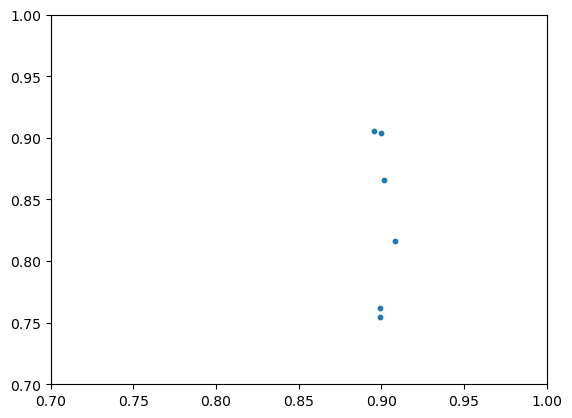

In [38]:
id_ = 116
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]]
plt.scatter(1-score_example[0],
            1-score_example[1], s=10)
plt.xlim(.7, 1)
plt.ylim(.7, 1)

In [39]:
label_table['polymer']

0     NH2SO4
1      NaNO3
2         PE
3         PP
4        PSL
5    sucrose
Name: polymer, dtype: object

In [42]:
top_hqi_values = pd.DataFrame(np.concatenate(score_list, axis=1))
top_hqi_values.columns = [x + ' (IR)' for x in label_table['polymer']] + [x + ' (Raman)' for x in label_table['polymer']]
top_hqi_values = pd.concat([top_hqi_values, IR_spectra_all.iloc[:,-6:-1]], axis=1)
top_hqi_values

all_hqi_values = pd.DataFrame(np.concatenate(score_all_list, axis=0).T)
#all_hqi_values.columns = list(rebecca_data_ir['id']) + list(rebecca_data_raman['id'])
#all_hqi_values = pd.concat([all_hqi_values, IR_spectra_all.iloc[:,-6:-1]], axis=1)
all_hqi_values

,0,1,2,3,4,5,6,7,8,9,...,527,528,529,530,531,532,533,534,535,536
0,0.432646,0.423384,0.391147,0.401404,0.440580,0.437564,0.429381,0.409268,0.418960,0.473945,...,0.260841,0.263838,0.260850,0.259063,0.260904,0.258329,0.264056,0.261239,0.258989,0.261919
1,0.301221,0.292368,0.271138,0.275419,0.299744,0.306632,0.294431,0.280590,0.282642,0.321780,...,0.179370,0.183530,0.177042,0.172401,0.178967,0.171823,0.183372,0.176988,0.174141,0.175058
2,0.418545,0.414359,0.391770,0.429534,0.386365,0.421869,0.413633,0.409934,0.430360,0.430385,...,0.280764,0.283035,0.280113,0.278248,0.280656,0.277357,0.284127,0.281271,0.278091,0.281336
3,0.432019,0.422219,0.389409,0.409047,0.432120,0.435627,0.426977,0.410824,0.423814,0.471774,...,0.677076,0.679513,0.677504,0.675606,0.676935,0.675350,0.679330,0.677290,0.675973,0.678594
4,0.278596,0.270642,0.245702,0.255066,0.276581,0.284818,0.271205,0.257070,0.261821,0.298793,...,0.457704,0.454814,0.454211,0.447340,0.454898,0.452418,0.448401,0.447544,0.456365,0.441613
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525,0.272322,0.266751,0.260933,0.252720,0.286978,0.272354,0.267765,0.261216,0.256909,0.297649,...,0.050548,0.049753,0.046086,0.046287,0.048609,0.048114,0.052690,0.048166,0.047271,0.045246
526,0.229372,0.226982,0.217129,0.211054,0.237073,0.230745,0.227091,0.219928,0.215912,0.249443,...,0.173881,0.164640,0.166657,0.172315,0.172118,0.171894,0.175559,0.172631,0.171374,0.172547
527,0.276842,0.273204,0.261465,0.257794,0.284773,0.279456,0.273775,0.266264,0.260972,0.297574,...,0.127115,0.125591,0.125452,0.126670,0.126515,0.126397,0.128172,0.127396,0.124977,0.126693
528,0.543505,0.535199,0.514715,0.504553,0.561240,0.548330,0.538674,0.520889,0.516619,0.580364,...,0.060886,0.063500,0.056324,0.054363,0.059478,0.054474,0.066331,0.059526,0.054290,0.055917


In [41]:
smx_all_IR_all = 1-np.power(smx_nn_all(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman_all = 1-np.power(smx_nn_all(x_train_raman, x_raman, label_train_Raman),1)
score_all_list = [smx_all_IR_all, smx_all_Raman_all]

In [25]:
smx_all_IR_rest = 1-np.power(smx_nn(x_train_ir, x_ir_rest, label_train_IR),1)
smx_all_Raman_rest = 1-np.power(smx_nn(x_train_raman, x_raman_rest, label_train_Raman),1)
score_list_rest = [smx_all_IR_rest, smx_all_Raman_rest]

In [26]:
smx_all_IR_rest_all = 1-np.power(smx_nn_all(x_train_ir, x_ir_rest, label_train_IR),1)
smx_all_Raman_rest_all = 1-np.power(smx_nn_all(x_train_raman, x_raman_rest, label_train_Raman),1)
score_list_rest_all = [smx_all_IR_rest_all, smx_all_Raman_rest_all]

In [61]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman)

(0.8169811320754717, 0.8264150943396227)

In [62]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman)

(0.8169811320754717, 0.8264150943396227)

In [63]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman)

(0.8169811320754717, 0.8264150943396227)

In [64]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman)

(0.8169811320754717, 0.8264150943396227)

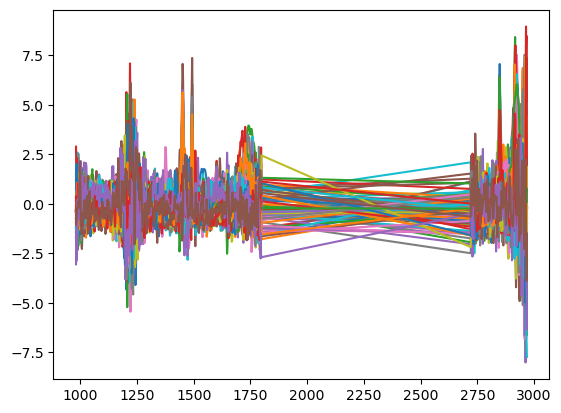

In [65]:
_ = plt.plot(IR_spectra_mix.query('polymer == "PSL"').iloc[:,:-8].T)

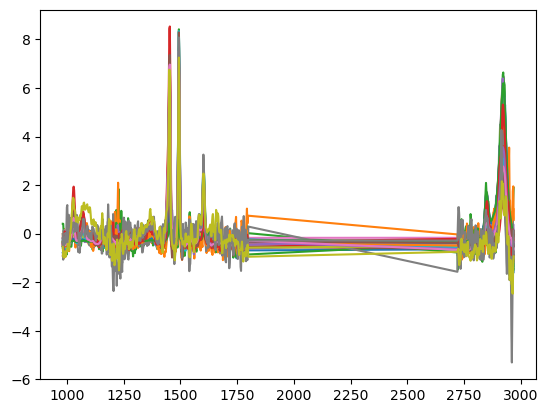

In [66]:
_ = plt.plot(rebecca_data_ir.query('polymer == "PSL"').iloc[:,:-4].T)

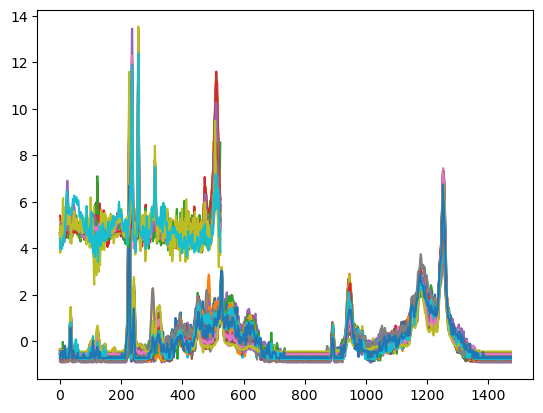

In [67]:
_= plt.plot(x_train_raman[label_train_Raman == 4].T)

_= plt.plot(x_train_ir[label_train_IR == 4].T+5)

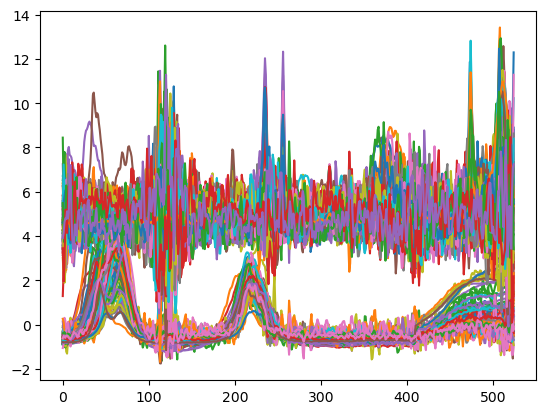

In [68]:
_= plt.plot(x_train_ir[label_train_IR == 0].T)

_= plt.plot(x_ir[label_ir == 4].T+5)

In [69]:
pd.DataFrame({'acc':np.argmin(score_list[1], 1) == label_ir,
 'label':label_table.iloc[label_ir,1]}).groupby('label').mean()

,acc
label,
NH2SO4,0.755556
NaNO3,0.230769
PE,0.815951
PP,0.840000
PSL,0.836735
sucrose,0.918919


In [70]:
pd.DataFrame({'acc':np.argmin(score_list[0], 1) == label_ir,
 'label':label_table.iloc[label_ir,1]}).groupby('label').mean()

,acc
label,
NH2SO4,0.933333
NaNO3,0.307692
PE,0.901840
PP,0.950000
PSL,0.520408
sucrose,0.846847


In [71]:
alphas = np.arange(0,.2,.01)
N_sim = 50


In [72]:

(df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis, df_res_all_mean_lis, df_res_cov_all_mean_lis, df_res_all_lis, df_res_cov_all_lis)  = experiment(score_list, 
                                                                                          label_ir, 
                                                                                          alphas,
                                                                                          N_sim, 
                                                                                          quant_prop=.2, 
                                                                                          cal_prop=0.8, 
                                                                                          seed_init=0)



100%|███████████████████████████████████████████| 20/20 [01:18<00:00,  3.93s/it]


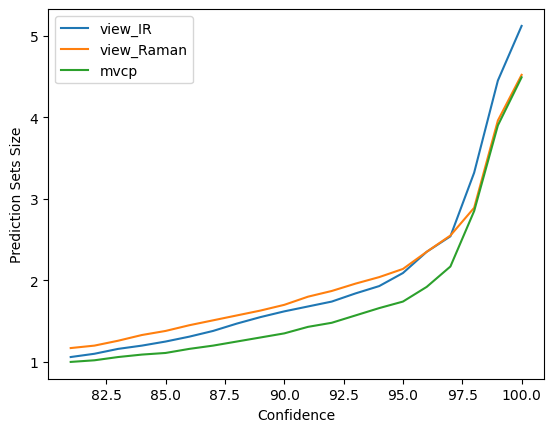

In [355]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

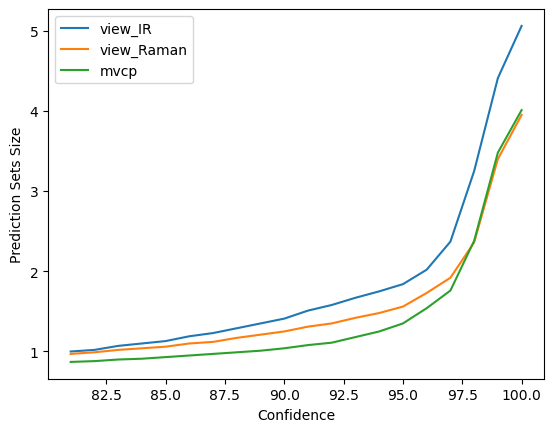

In [73]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

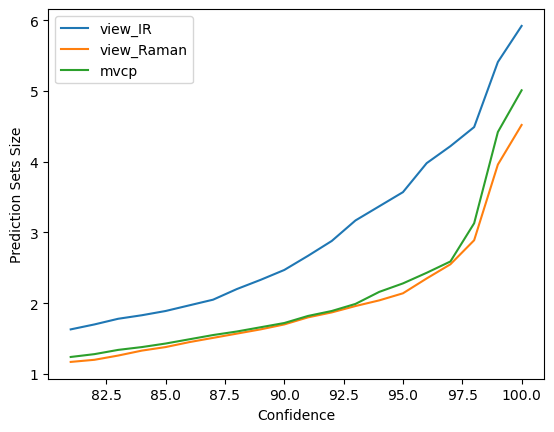

In [52]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

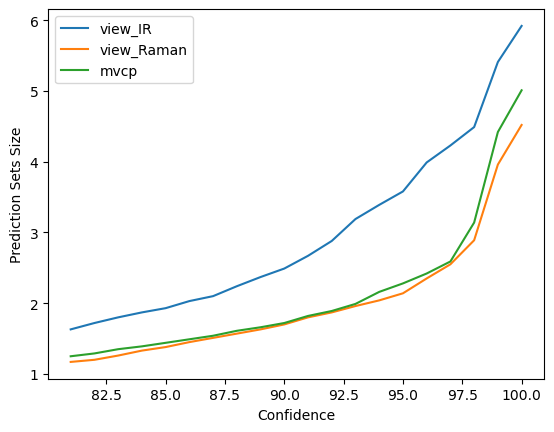

In [77]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

In [370]:
df_res_all = pd.concat([pd.concat(df_res_lis, axis=0), pd.concat(df_res_sd_lis, axis=0)],axis=1)
df_res_all.columns = ["mean set size "+x for x in df_res_all.columns[:3]] + ["standard deviation set size "+x for x in df_res_all.columns[3:]]
df_res_all['confidence'] = (1-alphas)*100
df_res_all

,mean set size view_IR,mean set size view_Raman,mean set size mvcp,standard deviation set size view_IR,standard deviation set size view_Raman,standard deviation set size mvcp,confidence
0,5.119294,4.522588,4.493882,0.247088,0.439425,0.473660,100.0
0,4.451294,3.958118,3.895294,0.375221,0.470883,0.503805,99.0
0,3.320471,2.894824,2.847765,0.367192,0.208788,0.442182,98.0
0,2.543059,2.547294,2.165647,0.217091,0.196865,0.268433,97.0
0,2.350353,2.352471,1.917412,0.204328,0.173784,0.191898,96.0
0,2.088941,2.139059,1.744235,0.224622,0.151255,0.166205,95.0
0,1.925412,2.037882,1.657647,0.173974,0.139532,0.141141,94.0
0,1.836706,1.960941,1.573882,0.153257,0.119563,0.117028,93.0
0,1.744706,1.867765,1.481176,0.138250,0.132006,0.113049,92.0
0,1.679294,1.801882,1.425647,0.133098,0.130712,0.100298,91.0


In [24]:
df_res_all.to_csv('results/data_fig_2.csv')

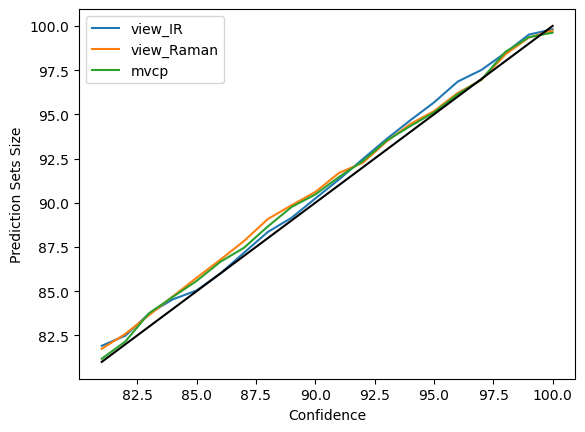

In [25]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
#np.round(df_res_all, 2)
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.plot(df_res_all['confidence'],df_res_all['confidence'], color='black')
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

In [372]:
(df_res_lis, 
 df_res_sd_lis, 
 df_res_cov_lis, 
 df_res_cov_sd_lis, 
 df_res_all_mean_lis, 
 df_res_cov_all_mean_lis,
 df_res_all_lis, 
 df_res_cov_all_lis)  = experiment(score_list, 
                                                                                          label_ir, 
                                                                                          [0.05],
                                                                                          N_sim, 
                                                                                          quant_prop=.2, 
                                                                                          cal_prop=0.8, 
                                                                                          seed_init=0)

100%|█████████████████████████████████████████████| 1/1 [00:04<00:00,  4.48s/it]


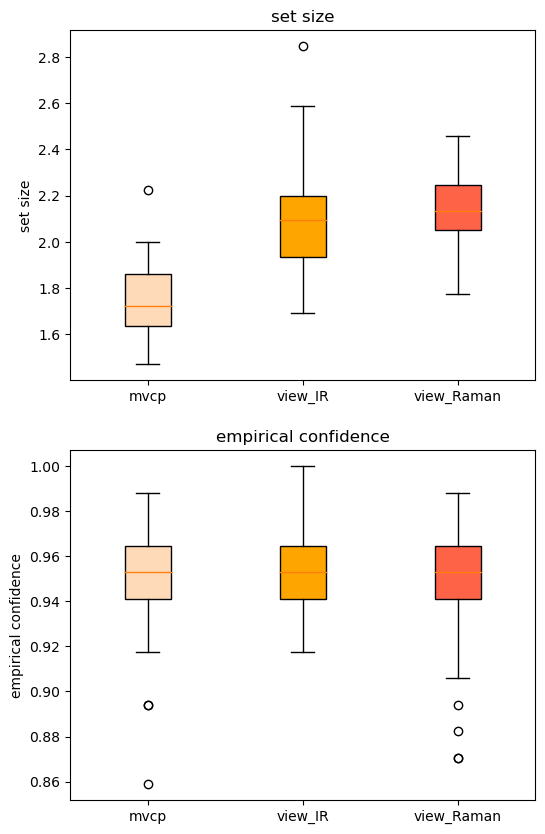

In [373]:
fig, ax = plt.subplots(nrows=2, figsize=(6, 10))
title = ['none', 'low', 'medium', 'high']
set_size = [np.array(df_res_all_mean_lis[0][x]) for x in df_res_all_mean_lis[0]]
cov = [np.array(df_res_cov_all_mean_lis[0][x]) for x in df_res_cov_all_mean_lis[0]]


labels = list(df_res_all_mean_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato']

ax[0].set_ylabel('set size')
ax[0].set_title('set size')

bplot = ax[0].boxplot(set_size,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
    
    
labels = list(df_res_cov_all_mean_lis[0].keys())   
ax[1].set_ylabel('empirical confidence')
ax[1].set_title('empirical confidence')

bplot = ax[1].boxplot(cov,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.show()

In [374]:
pd.concat([pd.DataFrame({'set_size_'+x:set_size[i] for i, x in enumerate(df_res_all_mean_lis[0])}),
              pd.DataFrame({'cov_'+x:cov[i] for i, x in enumerate(df_res_cov_all_mean_lis[0])})], axis=1).to_csv('results/data_fig_2c.csv')

In [519]:
table_fig2d = pd.DataFrame({'set_size':np.concatenate(df_res_all_lis[0]['mvcp']),
                            'cov':np.concatenate(df_res_cov_all_lis[0]['mvcp'])})#.groupby('set_size').sum()
table_fig2d = pd.concat([table_fig2d.groupby('set_size').count(),
                         table_fig2d.groupby('set_size').std(),
                         1-table_fig2d.groupby('set_size').std()], axis=1)
table_fig2d.columns = ['number of spectra', 'correct label in prediction set', 'correct label not in prediction set']
table_fig2d

,number of spectra,correct label in prediction set,correct label not in prediction set
set_size,,,
0,17,0.000000,1.000000
1,3001,0.176885,0.823115
2,364,0.295208,0.704792
3,258,0.347177,0.652823
4,291,0.300057,0.699943
5,168,0.077152,0.922848
6,151,0.000000,1.000000


In [527]:
df_res_all_lis[0].keys()

dict_keys(['mvcp', 'view_IR', 'view_Raman'])

In [74]:
def figure_2d(method):
    table_fig2d_list = []

    table_fig2d_aux = pd.DataFrame(np.zeros((7,3)))
    table_fig2d_aux.columns = ['number of spectra', 'correct label in prediction set', 'correct label not in prediction set']

    set_size_list_df = pd.DataFrame({'set_size':np.arange(7)})
    set_size_list_df

    for df_ss, df_cov in zip(df_res_all_lis[0][method], df_res_cov_all_lis[0][method]):
        table_fig2d = pd.DataFrame({'set_size':df_ss,
                                    'cov':df_cov})

        table_fig2d = pd.concat([table_fig2d.groupby('set_size').count(),
                                 table_fig2d.groupby('set_size').mean(),
                                 1-table_fig2d.groupby('set_size').mean()], axis=1)

        table_fig2d.columns = ['number of spectra', 'correct label in prediction set', 'correct label not in prediction set']
        table_fig2d = table_fig2d.reset_index()
        table_fig2d = pd.merge(set_size_list_df, table_fig2d, on='set_size', how='left')
        table_fig2d[np.isnan(table_fig2d)] = 0
        table_fig2d_aux = table_fig2d_aux + table_fig2d.iloc[:,1:]
        table_fig2d_list.append(table_fig2d)

    table_fig2d_aux = table_fig2d_aux / np.array([np.array([50]*7),
              np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list])),
              np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list]))]).T

    table_fig2d_aux['set_size'] = range(7)
    table_fig2d_aux = table_fig2d_aux.set_index('set_size')

    table_fig2d_aux_std = pd.DataFrame(np.sqrt(np.sum([np.array(1*(x.iloc[:,1]>0))[:,None]*(x.iloc[:,1:]-table_fig2d_aux)**2 for x in table_fig2d_list], 0)/
                         np.array([np.array([50]*7),
                                   np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list])),
                                   np.array(sum([df.iloc[:,2:].sum(1) for df in table_fig2d_list]))]).T))

    table_fig2d_aux_std.columns = table_fig2d_aux.columns

    table_fig2d_aux_std['set_size'] = range(7)
    table_fig2d_aux_std = table_fig2d_aux_std.set_index('set_size')
    table_fig2d_aux_std.columns = [x+' (standard deviation)' for x in table_fig2d_aux_std.columns]

    table_fig2d_aux.columns = [x+' (mean)' for x in table_fig2d_aux.columns]

    return pd.concat([table_fig2d_aux, table_fig2d_aux_std], axis=1)#.to_csv('results/data_fig_2d.csv')

for method in ['mvcp', 'view_IR', 'view_Raman']:
    print(figure_2d(method))

          number of spectra (mean)  correct label in prediction set (mean)  \
set_size                                                                     
0                             0.00                                     NaN   
1                            16.16                                0.993687   
2                             9.62                                0.995111   
3                             6.60                                1.000000   
4                             9.94                                0.996750   
5                             9.78                                1.000000   
6                            32.90                                1.000000   

          correct label not in prediction set (mean)  \
set_size                                               
0                                                NaN   
1                                           0.006313   
2                                           0.004889   
3                

In [521]:
pd.concat([table_fig2d_aux, table_fig2d_aux_std], axis=1)#.to_csv('results/data_fig_2d.csv')

,number of spectra (mean),correct label in prediction set (mean),correct label not in prediction set (mean),number of spectra (standard deviation),correct label in prediction set (standard deviation),correct label not in prediction set (standard deviation)
set_size,,,,,,
0,0.34,0.000000,1.000000,0.511046,0.000000,0.000000
1,60.02,0.968087,0.031913,4.397681,0.020699,0.020699
2,7.28,0.908773,0.091227,2.332724,0.098756,0.098756
3,5.16,0.872270,0.127730,2.185040,0.182646,0.182646
4,5.82,0.916940,0.083060,2.896135,0.117534,0.117534
5,3.36,0.996528,0.003472,1.771670,0.023804,0.023804
6,3.02,1.000000,0.000000,2.383346,0.000000,0.000000


In [596]:
table_fig2d_aux.to_csv('results/data_fig_2d.csv')

In [584]:
sum(table_fig2d_aux['number of spectra']*table_fig2d_aux.index)/sum(table_fig2d_aux['number of spectra'])

1.5394742976060476

In [431]:
sum(table_fig2d['number of spectra']*table_fig2d.index)/sum(table_fig2d['number of spectra'])

1.5380999505195447

In [566]:
table_fig2d_list[0]

,set_size,number of spectra,correct label in prediction set,correct label not in prediction set
0,0,2,0.000000,1.000000
1,1,58,0.965517,0.034483
2,2,10,1.000000,0.000000
3,3,7,0.857143,0.142857
4,4,3,1.000000,0.000000
5,5,1,1.000000,0.000000
6,6,4,1.000000,0.000000


In [380]:
ids_example = [130, 136, 217]

In [381]:
pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[281:282,:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
281,-0.385112,-0.372411,-0.323185,-0.343063,-0.378068,-0.37546,-0.3905,-0.43211,-0.414806,-0.370172,...,-0.15191,-0.031315,0,0,LDPE,LDPE,NaN,PE,139,no_background


In [382]:
pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[277:278,:]


,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
277,-0.331342,-0.392422,-0.507704,-0.478653,-0.356794,-0.309025,-0.318151,-0.239069,-0.144421,-0.22609,...,-0.429705,-0.617534,0,0,LDPE,LDPE,NaN,PE,132,no_background


In [383]:
IR_spectra_mix_std_rest.shape
pd.concat([IR_spectra_mix_std_rest, IR_spectra_mix_rest], axis=0).reset_index(drop=True).query('id in @ids_example')

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
138,-0.580840,-0.575939,-0.561041,-0.544883,-0.548383,-0.558500,-0.555964,-0.556645,-0.572358,-0.571250,...,-0.431521,-0.429762,0,0,PSL,MIX,PSL AND SN?,MIXTURE,217,no_background
172,-0.061813,-0.495358,0.555116,0.750589,0.169358,0.425192,-0.654958,-1.672618,-0.539975,0.142778,...,4.257040,1.043177,0,0,UNS,LOW,FLUORESCENCE,UNSORTED,136,background
330,-0.458293,-0.381986,-0.291597,-0.071482,0.102961,0.042253,-0.242010,-0.278758,-0.181451,-0.101000,...,-0.754732,-0.923426,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,136,no_background
333,-0.596220,-0.590548,-0.590095,-0.600481,-0.602661,-0.594409,-0.589836,-0.580672,-0.558146,-0.550383,...,1.858261,1.505509,0,0,MIX,MIX,LDPE AND PP?,MIXTURE,217,no_background


In [400]:
IR_spectra_mix_std.query('id == 130')

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
63,-0.483224,-0.443826,-0.399688,-0.356638,-0.320509,-0.284437,-0.256681,-0.241777,-0.239936,-0.246151,...,1.810975,1.684473,0,0,SCR,SCR,NaN,sucrose,130,no_background


In [70]:
id_ = 68
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]] # id == 138
print(pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[id_:id_+1,:]['id'])

id_ = 276
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]] # id == 130
print(pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[id_:id_+1,:]['id'])

#[71, 116,161, 174]
id_ = 519
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]] # id == 130
print(pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[id_:id_+1,:]['id'])

#score_example = [score_list_rest[0][330:331], score_list_rest[1][330:331]]
#print(pd.concat([IR_spectra_mix_std_rest, IR_spectra_mix_rest], axis=0).reset_index(drop=True).iloc[330:331,:]['id'])

#score_example = [score_list_rest[0][333:334], score_list_rest[1][333:334]]
#print(pd.concat([IR_spectra_mix_std_rest, IR_spectra_mix_rest], axis=0).reset_index(drop=True).iloc[333:334,:]['id'])


68    138
Name: id, dtype: int64
276    130
Name: id, dtype: int64
519    634
Name: id, dtype: int64


519    634
Name: id, dtype: int64

In [73]:
label_table.iloc[label_ir[id_],1]

'PE'

In [74]:
pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[id_:id_+1,:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
519,0.644701,-0.752731,-0.192524,0.396841,-0.117083,-0.547084,-0.032332,0.329842,-0.537588,-0.71549,...,4.43446,4.388588,0,0,LDPE,LOW,NaN,PE,634,no_background


In [46]:
label_table.iloc[(label_ir[id_]),:]

label       2
polymer    PE
Name: 2, dtype: object

In [31]:
score_list[0].shape

(530, 6)

In [49]:
score_example_all = [score_all_list[0][:,281:282], score_all_list[1][:,281:282]] # id == 138
score_example_all

[array([[0.74707808],
        [0.74244261],
        [0.72086531],
        [0.71419862],
        [0.75747543],
        [0.75294024],
        [0.74298862],
        [0.72803595],
        [0.72170678],
        [0.77547579],
        [0.71930528],
        [0.68061967],
        [0.76249542],
        [0.73173492],
        [0.70784477],
        [0.74052521],
        [0.7525006 ],
        [0.73370711],
        [0.75677654],
        [0.72870902],
        [0.7148282 ],
        [0.75498932],
        [0.71672232],
        [0.75119779],
        [0.75543349],
        [0.57713036],
        [0.73355883],
        [0.76235655],
        [0.75081692],
        [0.72927454],
        [0.76142177],
        [0.76519811],
        [0.75561051],
        [0.74818898],
        [0.75316209],
        [0.75719506],
        [0.53759048],
        [0.76177056],
        [0.50719645],
        [0.70559026],
        [0.70255861],
        [0.74826409],
        [0.54434491],
        [0.53551901],
        [0.50810377],
        [0

In [48]:
pd.DataFrame({"1-hqi":score_example_all[0].flatten(),
              "polymer":label_table.iloc[label_train_IR,1].reset_index(drop=True),
              "id_ref":rebecca_data_ir['id']}).to_csv('results/hqi_example_138_IR_data_fig_1.csv')#.groupby('polymer').min()


In [50]:
pd.DataFrame({"1-hqi":score_example_all[1].flatten(),
              "polymer":label_table.iloc[label_train_Raman,1].reset_index(drop=True),
              "id_ref":rebecca_data_raman['id']}).to_csv('results/hqi_example_138_Raman_data_fig_1.csv')#.groupby('polymer').min()

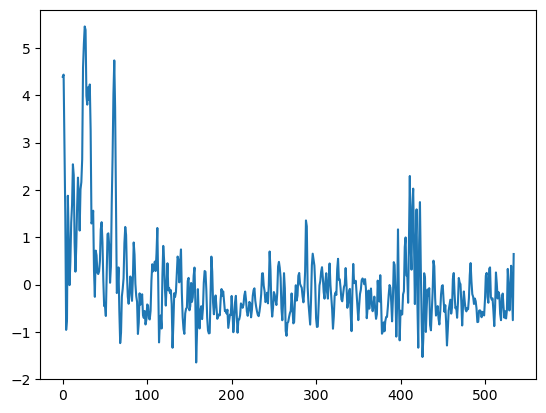

In [76]:
_ = plt.plot(np.array(IR_spectra_mix.query('id == 634').iloc[0,:-8])[::-1].T)
#_ = plt.plot(np.array(IR_spectra_mix_rest.query('id == 217').iloc[0,:-8])[::-1].T)

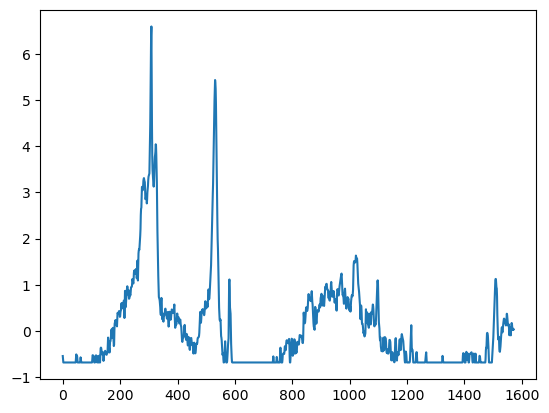

In [77]:
_ = plt.plot(np.array(Raman_spectra_mix.query('id == 634').iloc[0,:-4])[::-1].T)
#_ = plt.plot(np.array(Raman_spectra_mix_rest.query('id == 217').iloc[0,:-4])[::-1].T)

In [78]:
score_list[0].shape

(530, 6)

  0%|                                                     | 0/5 [00:00<?, ?it/s]

MVCP ['PE']
IR []
Raman []


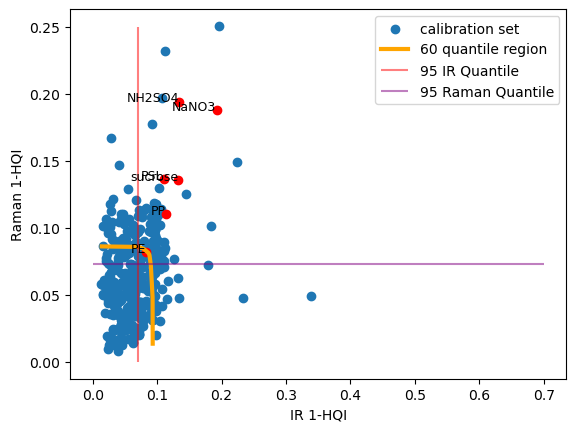

 20%|█████████                                    | 1/5 [00:00<00:02,  1.76it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


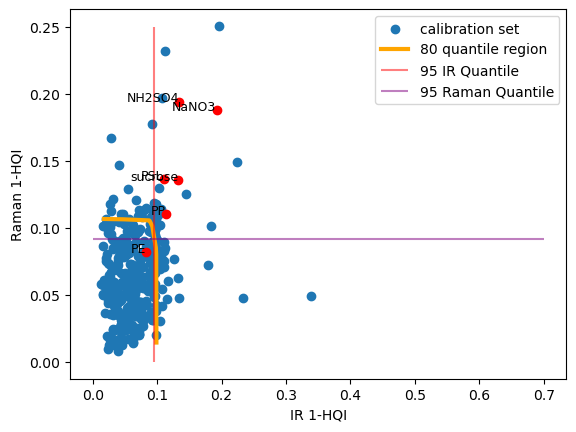

 40%|██████████████████                           | 2/5 [00:00<00:01,  2.43it/s]

MVCP ['PE']
IR ['PE']
Raman ['PE']


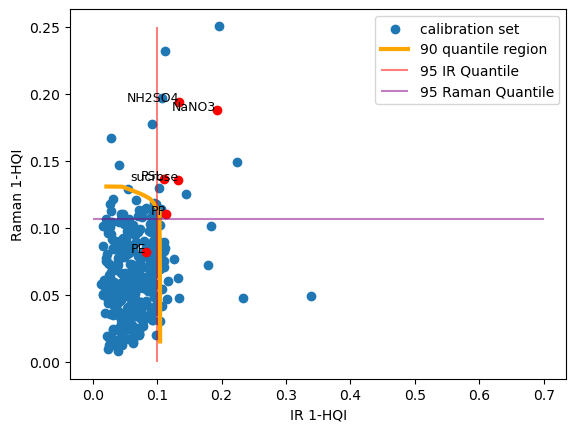

 60%|███████████████████████████                  | 3/5 [00:01<00:00,  2.73it/s]

MVCP ['PE', 'PP']
IR ['PE', 'PSL']
Raman ['PE', 'PP']


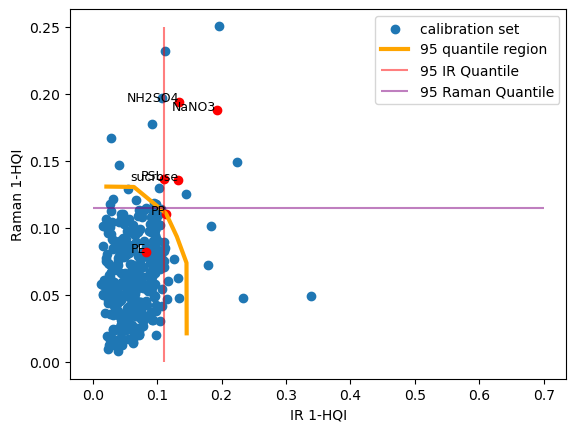

 80%|████████████████████████████████████         | 4/5 [00:01<00:00,  2.94it/s]

MVCP ['PE', 'PP', 'PSL', 'sucrose']
IR ['NH2SO4', 'PE', 'PP', 'PSL', 'sucrose']
Raman ['PE', 'PP', 'PSL', 'sucrose']


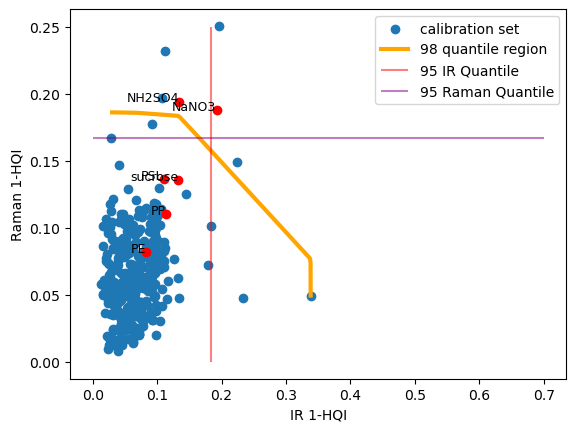

100%|█████████████████████████████████████████████| 5/5 [00:01<00:00,  3.02it/s]


In [79]:
ps_list, ps_ir_list, ps_raman_list, env_list, cal_smx_arr, cal_idx_list, q_ir_list, q_raman_list = envelop(score_list, label_ir, score_example,
alphas=[0.40,.20, .10, 0.05, 0.02],
#alphas=[.05],
N_sim=1, 
quant_prop=.2, 
cal_prop=0.8, 
seed_init=0)

  0%|                                                     | 0/5 [00:00<?, ?it/s]

MVCP []
IR []
Raman []


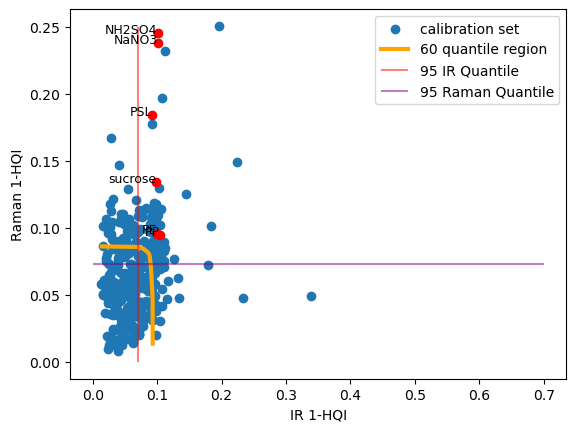

 20%|█████████                                    | 1/5 [00:00<00:02,  1.64it/s]

MVCP []
IR ['PSL']
Raman []


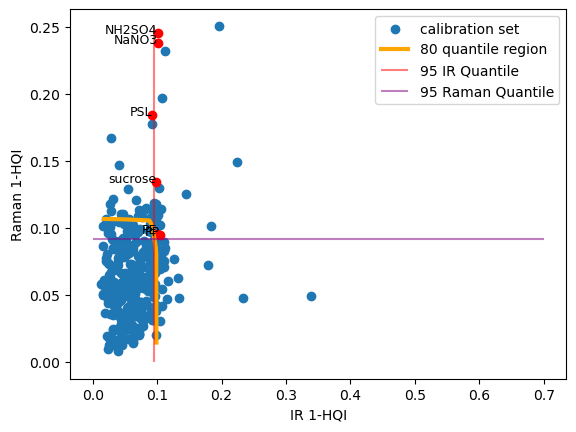

 40%|██████████████████                           | 2/5 [00:00<00:01,  2.28it/s]

MVCP ['PE']
IR ['PSL', 'sucrose']
Raman ['PE', 'PP']


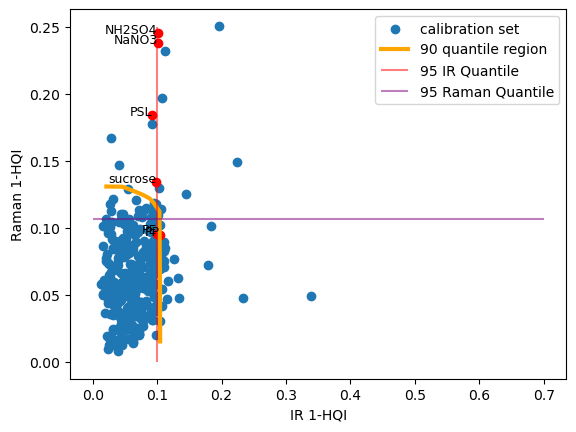

 60%|███████████████████████████                  | 3/5 [00:01<00:00,  2.57it/s]

MVCP ['PE', 'PP']
IR ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']
Raman ['PE', 'PP']


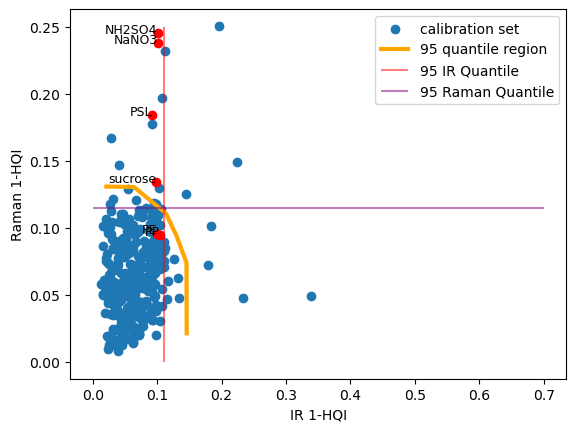

 80%|████████████████████████████████████         | 4/5 [00:01<00:00,  2.81it/s]

MVCP ['PE', 'PP', 'PSL', 'sucrose']
IR ['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']
Raman ['PE', 'PP', 'sucrose']


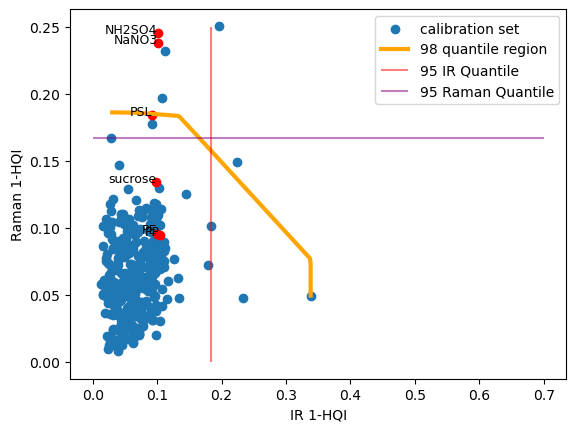

100%|█████████████████████████████████████████████| 5/5 [00:01<00:00,  2.86it/s]


In [22]:
ps_list, ps_ir_list, ps_raman_list, env_list, cal_smx_arr, cal_idx_list, q_ir_list, q_raman_list = envelop(score_list, label_ir, score_example,
alphas=[0.40,.20, .10, 0.05, 0.02],
#alphas=[.05],
N_sim=1, 
quant_prop=.2, 
cal_prop=0.8, 
seed_init=0)

In [614]:
#IR_spectra_calibration = 
IR_spectra_all.loc[~cal_idx_list[5][0][0],].loc[cal_idx_list[5][0][1],'id']#, 
#Raman_spectra_calibration = Raman_spectra_all.loc[~cal_idx_list[5][0][0],].loc[cal_idx_list[5][0][1],]#, Raman_spectra_all


0        1
1        2
3        8
4       10
5       11
      ... 
523    651
524    653
526    661
528    670
529    672
Name: id, Length: 339, dtype: int64

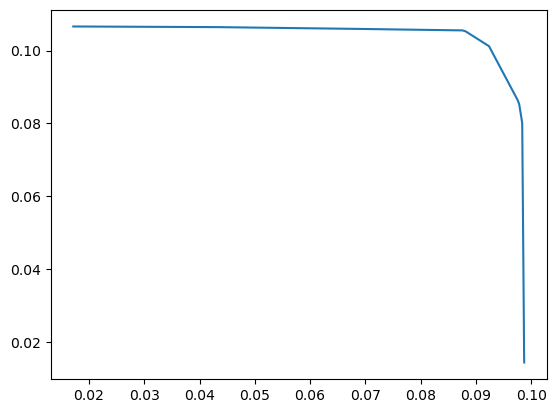

In [55]:
_ = plt.plot(env_list[20][0][0],
env_list[20][0][1])

In [56]:
ps_list, ps_ir_list, ps_raman_list, q_ir_list, q_raman_list

(defaultdict(list,
             {40: [[]],
              20: [[]],
              10: [['PE']],
              5: [['PE', 'PP']],
              2: [['PE', 'PP', 'PSL', 'sucrose']]}),
 defaultdict(list,
             {40: [[]],
              20: [['PSL']],
              10: [['PSL', 'sucrose']],
              5: [['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']],
              2: [['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose']]}),
 defaultdict(list,
             {40: [[]],
              20: [[]],
              10: [['PE', 'PP']],
              5: [['PE', 'PP']],
              2: [['PE', 'PP', 'sucrose']]}),
 defaultdict(list,
             {40: [0.07056918326282047],
              20: [0.09439805730755213],
              10: [0.09962051665001559],
              5: [0.11030437120822534],
              2: [0.1827346556399314]}),
 defaultdict(list,
             {40: [0.0727075810639487],
              20: [0.09141820295844538],
              10: [0.10628537712456665],
              5: [0.1

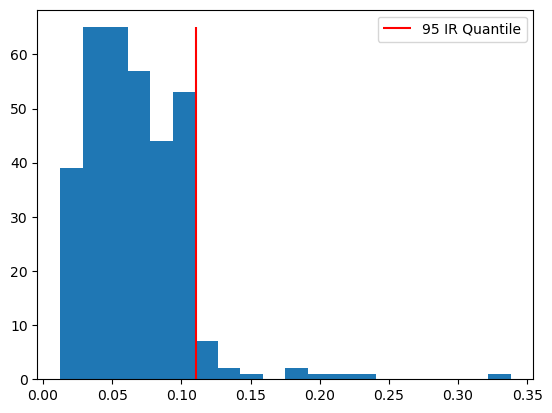

In [57]:
h_ir = plt.hist(cal_smx_arr[0],bins=20, density=False)
_ = plt.vlines(x= q_ir_list[5],
                ymin=0,
                ymax=65,
                colors='red',
                alpha=1,
                linestyles='solid',
                label='95 IR Quantile')
_ = plt.legend()

In [58]:
len(env_list[40][0])

2

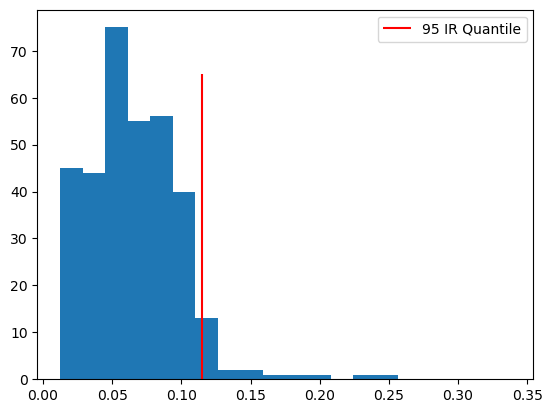

In [59]:
h_raman = plt.hist(cal_smx_arr[1],bins=h_ir[1], density=False)
_ = plt.vlines(x= q_raman_list[5],
                ymin=0,
                ymax=65,
                colors='red',
                alpha=1,
                linestyles='solid',
                label='95 IR Quantile')
_ = plt.legend()

In [60]:
h_ir[1]

array([0.0122862 , 0.02858032, 0.04487443, 0.06116855, 0.07746266,
       0.09375678, 0.11005089, 0.12634501, 0.14263912, 0.15893324,
       0.17522735, 0.19152147, 0.20781558, 0.2241097 , 0.24040381,
       0.25669793, 0.27299204, 0.28928616, 0.30558028, 0.32187439,
       0.33816851])

In [61]:
pd.DataFrame({'1-HQI':h_ir[1][:-1], 
              '# IR':h_ir[0],
              '# Raman':h_raman[0]
              })#.to_csv('results/hist_data_fig_2a.csv')

,1-HQI,# IR,# Raman
0,0.012286,39.0,45.0
1,0.028580,65.0,44.0
2,0.044874,65.0,75.0
3,0.061169,57.0,55.0
4,0.077463,44.0,56.0
5,0.093757,53.0,40.0
6,0.110051,7.0,13.0
7,0.126345,2.0,2.0
8,0.142639,1.0,2.0
9,0.158933,0.0,1.0


In [426]:
cal_smx_arr[0].shape

(339,)

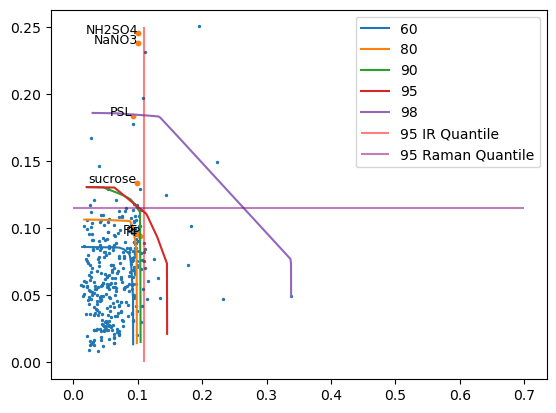

In [62]:
plt.scatter(cal_smx_arr[0],
            cal_smx_arr[1], s=2)

plt.scatter(score_example[0],
            score_example[1], s=10)

for i in range(6):
    plt.text(score_example[0][0, i], 
             score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')

env_data_list = []
for env in env_list:
    env_data = pd.DataFrame(np.array(env_list[env][0]).T)
    env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
    _ = plt.plot(env_data['x - '+str(100-env)],
                 env_data['y - '+str(100-env)], label=str(100-env))
    env_data_list.append(env_data)

q_ir_list, q_raman_list
_ = plt.vlines(x= q_ir_list[5][0],
                ymin=0,
                ymax=.25,
                colors='r',
                alpha=.5,
                linestyles='solid',
                label='95 IR Quantile')

_ = plt.hlines(y= q_raman_list[5][0],
                            xmin=0,
                            xmax=.7,
                            colors='purple',
                            alpha=.5,
                            linestyles='solid',
                            label='95 Raman Quantile')

_ = plt.legend()

In [69]:
IR_spectra_all.iloc[519:520,:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
519,0.644701,-0.752731,-0.192524,0.396841,-0.117083,-0.547084,-0.032332,0.329842,-0.537588,-0.71549,...,4.43446,4.388588,0,0,LDPE,LOW,NaN,PE,634,no_background


519 PE


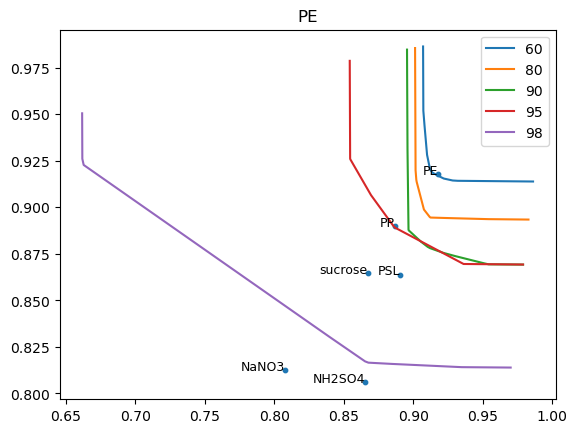

522 PSL


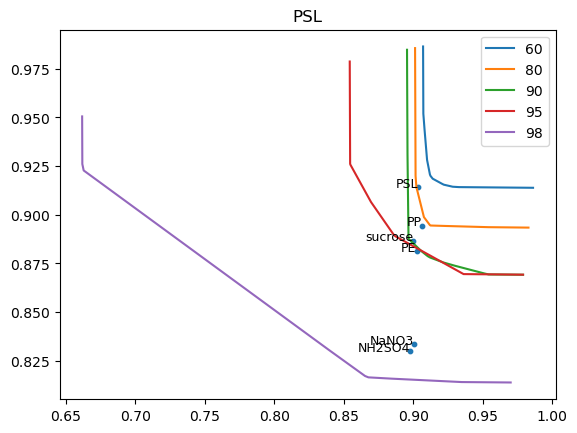

262 PP


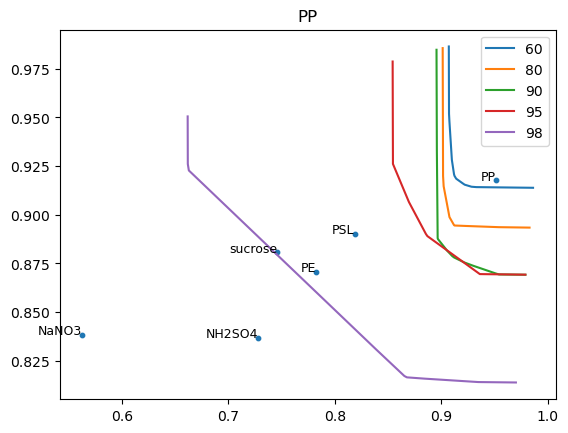

524 PE


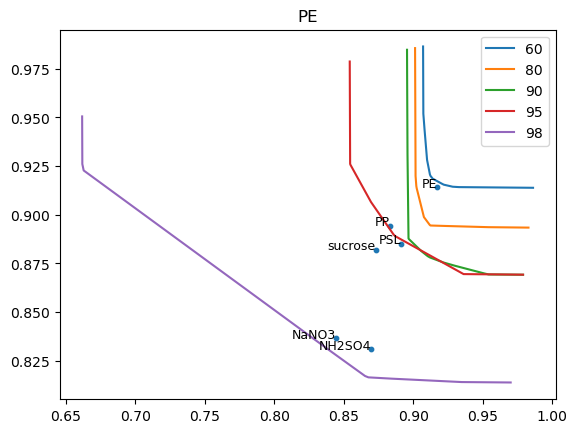

43 NaNO3


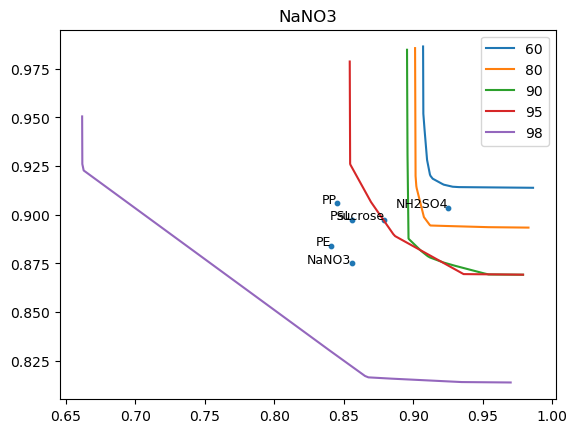

64 NaNO3


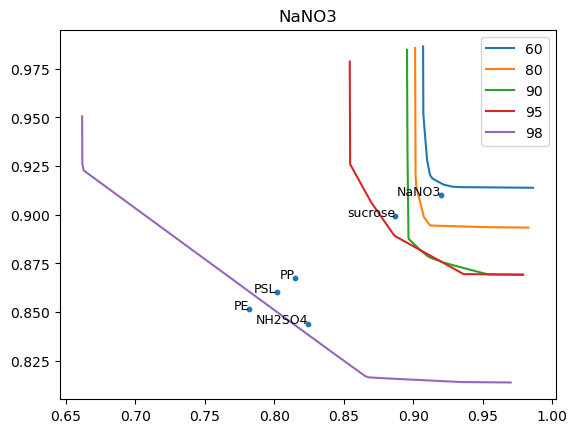

87 sucrose


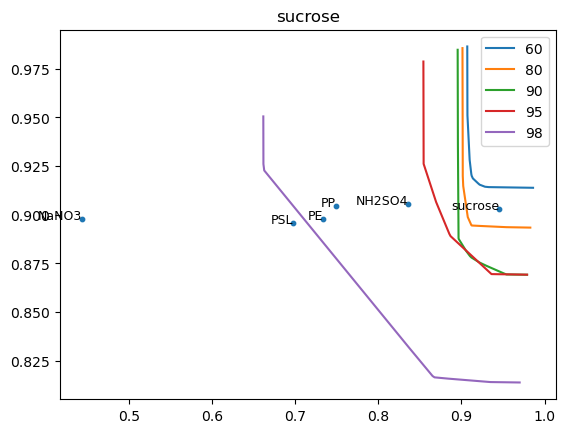

113 PE


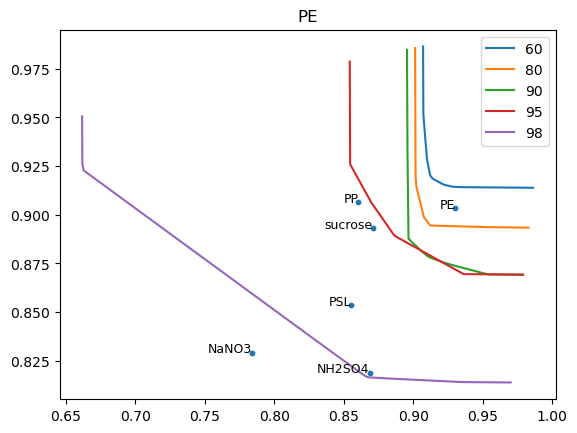

129 NH2SO4


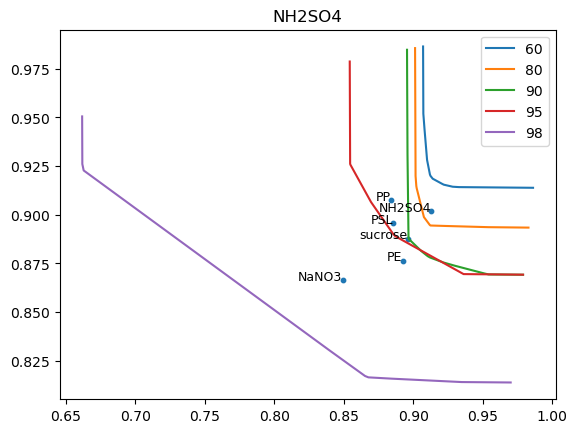

145 NaNO3


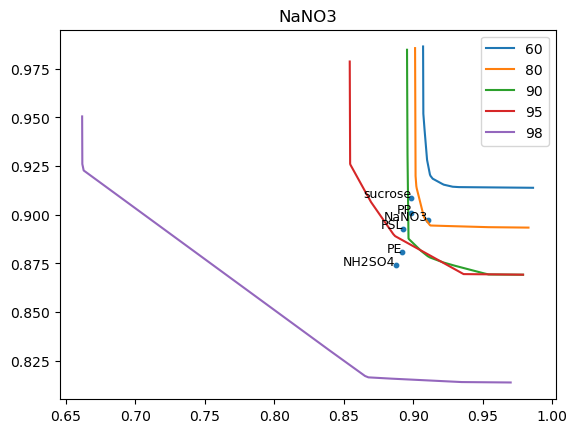

5 NaNO3


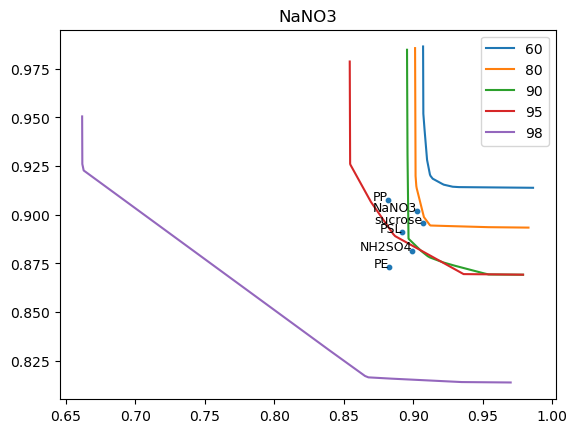

70 NH2SO4


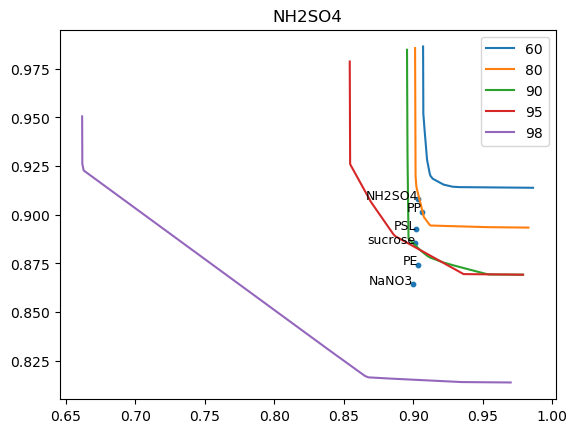

226 PP


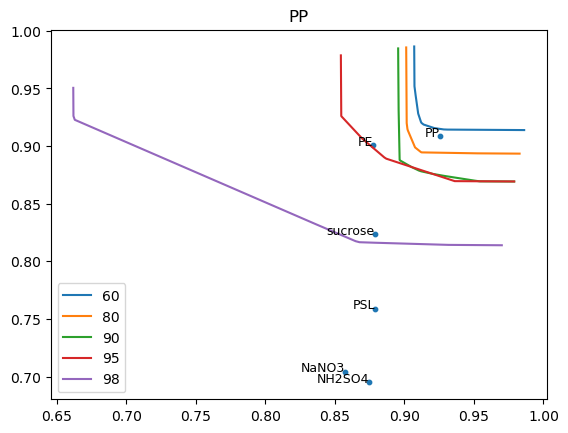

248 PSL


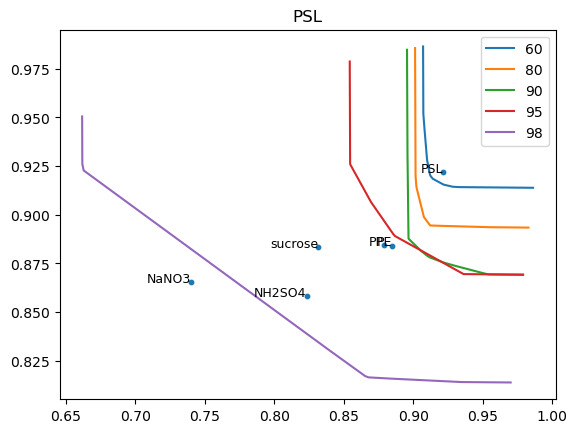

255 PSL


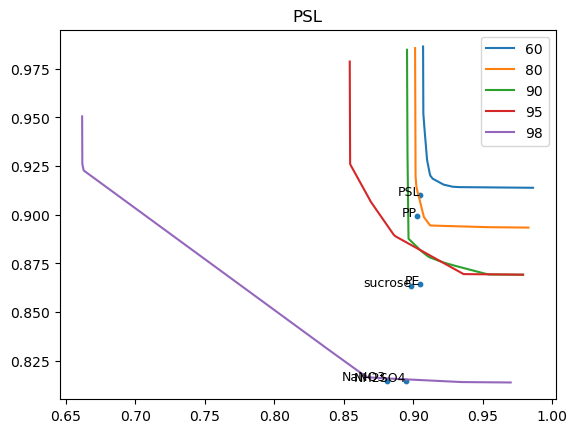

261 PE


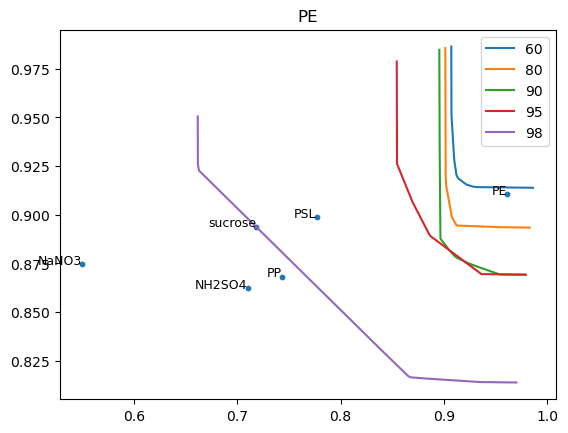

265 PP


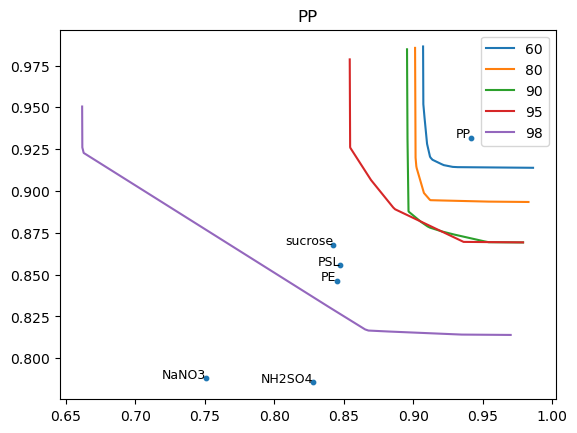

269 PE


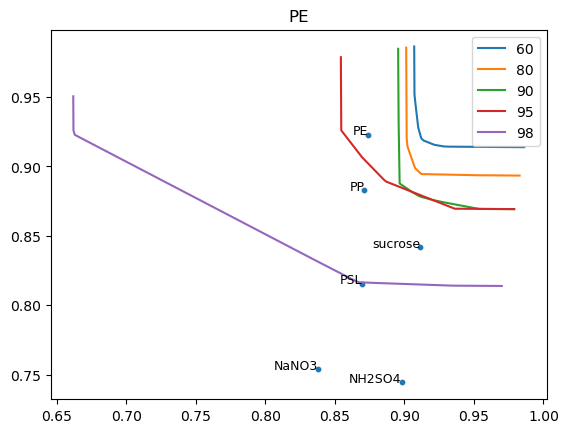

273 PE


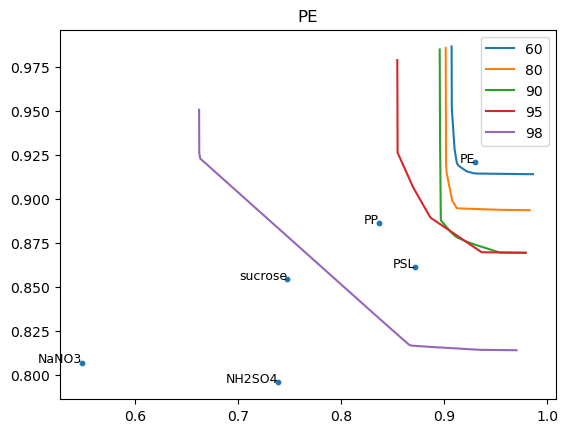

298 PE


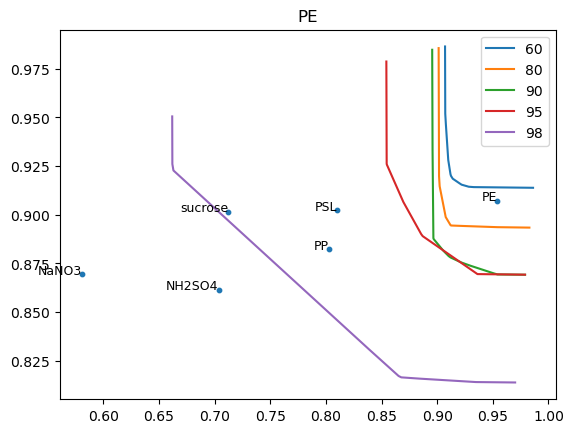

302 PP


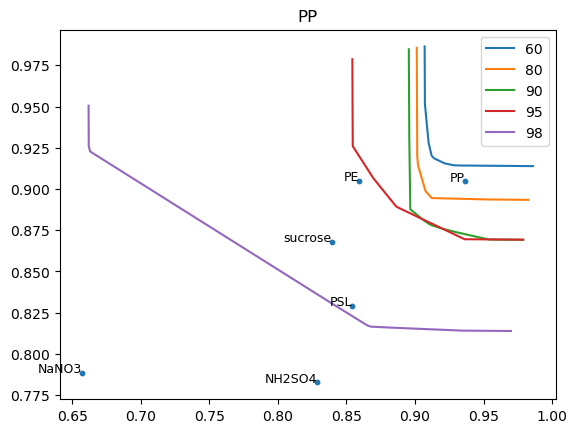

324 PE


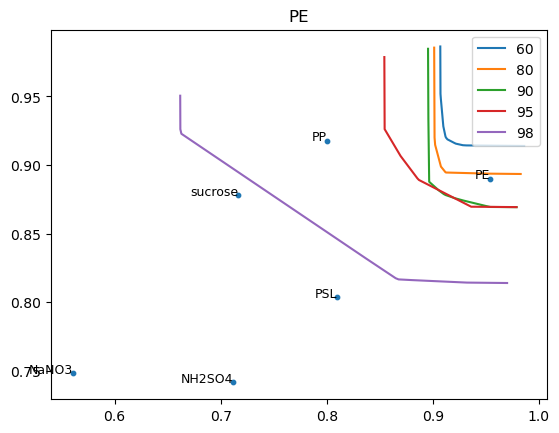

334 PP


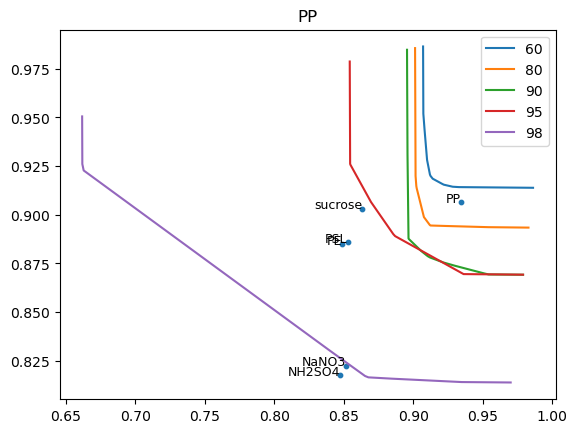

345 PSL


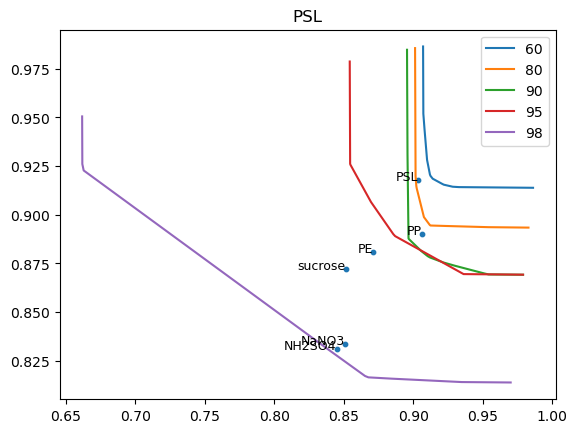

415 PP


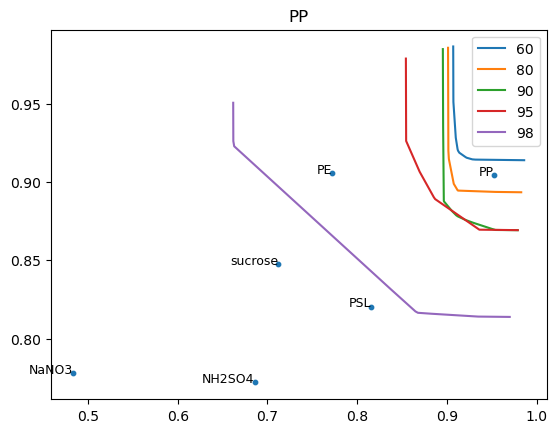

419 PE


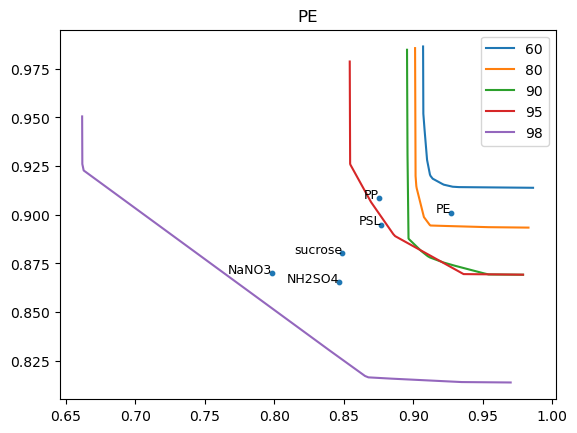

438 PE


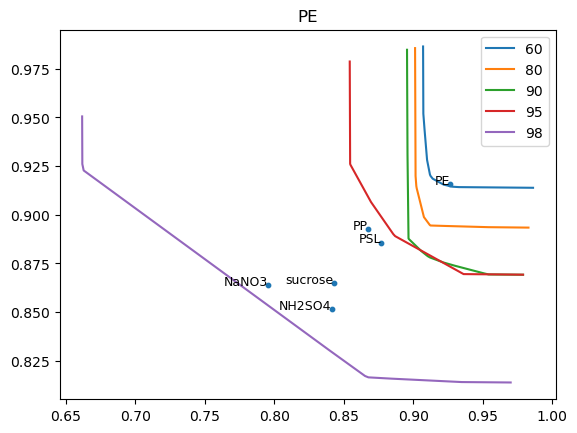

In [63]:
good_examples = [5, 29, 39, 41, 43, 60, 65, 71, 75, 100, 111, 113, 115, 116, 129, 130, 145, 161, 168, 171, 174, 181, 186, 201]

good_examples = [519, 522, 262, 524,43, 64, 87, 113, 129, 145, 5, 70, 226, 248, 255, 261, 265, 269, 273, 298, 302, 324, 334, 345, 415, 419, 438]

for j in good_examples:
    print(j, label_table.iloc[label_ir[j],1])
    plt.scatter(1-score_list[0][j, :],
                1-score_list[1][j, :], s=10)
    for i in range(6):
        plt.text(1-score_list[0][j, i], 
                 1-score_list[1][j, i], label_table.iloc[i,1], fontsize=9, ha='right')

    for env in env_list:
        env_data = pd.DataFrame(np.array(env_list[env][0]).T)
        env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
        _ = plt.plot(1-env_data['x - '+str(100-env)],
                     1-env_data['y - '+str(100-env)], label=str(100-env))

    _ = plt.title(label_table.iloc[label_ir[j],1])
    _ = plt.legend() 
    #_ = plt.savefig('plots_examples_hqi/example_'+label_table.iloc[label_ir[j],1]+'_plot_'+str(j)+'.png')
    _ = plt.show()
    


In [103]:
#'example_'+
label_table.iloc[label_ir[j],1]#+'_plot_'+str(j)+'.png'

'PE'

In [429]:
cal_data = pd.DataFrame(cal_smx_arr.T)
cal_data.columns = ['IR', 'Raman']
cal_data#.to_csv('results/calibration_data_fig_1.csv')
cal_data

,IR,Raman
0,0.033002,0.044741
1,0.057135,0.052643
2,0.024109,0.030193
3,0.043478,0.032081
4,0.100308,0.121281
...,...,...
334,0.037226,0.041521
335,0.082613,0.052943
336,0.069389,0.051313
337,0.042864,0.065551


In [430]:
env_data = pd.concat([env_data_60, env_data_80, env_data_90, env_data_95],axis=1)
env_data#.to_csv('results/envelopes_data_fig_1.csv')
env_data

,x - 60,y - 60,x - 80,y - 80,x - 90,y - 90,x - 95,y - 95
0,0.014850,0.085617,0.019645,0.113261,0.024255,0.139840,0.030215,0.174198
1,0.016996,0.085604,0.022484,0.113244,0.027760,0.139819,0.034581,0.174172
2,0.018589,0.085595,0.024590,0.113232,0.030361,0.139804,0.037821,0.174153
3,0.020582,0.085583,0.027228,0.113217,0.033617,0.139785,0.041877,0.174129
4,0.021082,0.085580,0.027889,0.113213,0.034434,0.139780,0.042894,0.174123
...,...,...,...,...,...,...,...,...
334,0.092980,0.029066,0.101400,0.031698,0.113653,0.035528,0.148230,0.046337
335,0.093002,0.024961,0.101424,0.027221,0.113680,0.030510,0.148265,0.039793
336,0.093008,0.023987,0.101430,0.026159,0.113687,0.029320,0.148273,0.038240
337,0.093022,0.021369,0.101445,0.023304,0.113704,0.026121,0.148296,0.034067


In [495]:
pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[id_:id_+1,:]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
116,-1.858163,0.530297,2.348643,1.245871,0.131951,-0.210527,0.305258,-0.155265,-0.445633,0.468599,...,-2.856548,-5.539007,0,0,LDPE,LOW,NaN,PE,199,background


In [500]:
IR_spectra_mix_std.query('id == 199')

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background
116,-1.858163,0.530297,2.348643,1.245871,0.131951,-0.210527,0.305258,-0.155265,-0.445633,0.468599,...,-2.856548,-5.539007,0,0,LDPE,LOW,NaN,PE,199,background


In [501]:
id_ = 116
#score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]] # id == 130
print(pd.concat([IR_spectra_mix_std, IR_spectra_mix], axis=0).reset_index(drop=True).iloc[id_,-2])


199


In [502]:
hqi_ex = pd.DataFrame({'polymer':label_table['polymer'],
              '(HQI) IR':1-score_example[0][0], 
              '(HQI) Raman':1-score_example[1][0]})
#hqi_ex.to_csv('results/hqi_example_data_fig_1_id_217.csv')
hqi_ex

,polymer,(HQI) IR,(HQI) Raman
0,NH2SO4,0.905652,0.768586
1,NaNO3,0.904016,0.701773
2,PE,0.894303,0.924703
3,PP,0.890097,0.880080
4,PSL,0.889344,0.751490
5,sucrose,0.902026,0.849071


In [428]:
score_example

[array([[0.41299537, 0.5262726 , 0.03149208, 0.30548167, 0.26839426,
         0.39223105]]),
 array([[0.07436085, 0.13966643, 0.12139071, 0.1222269 , 0.14048021,
         0.13264733]])]

,confidence,MVCP (IR + Raman),CP (IR),CP (Raman)
0,60,[],[],[]
1,80,[],[],[PE]
2,90,"[PE, PP]","[NH2SO4, NaNO3, PE, sucrose]",[PE]
3,95,"[PE, PP, sucrose]","[NH2SO4, NaNO3, PE, PP, PSL, sucrose]","[PE, PP]"
4,98,"[NH2SO4, PE, PP, sucrose]","[NH2SO4, NaNO3, PE, PP, PSL, sucrose]","[PE, PP, sucrose]"


In [512]:
pred_sets_ex = pd.concat([(pd.DataFrame(ps_list).T), 
 (pd.DataFrame(ps_ir_list).T),
 (pd.DataFrame(ps_raman_list).T)],axis=1).reset_index()
pred_sets_ex['index'] = 100 - pred_sets_ex['index']
pred_sets_ex.columns = ['confidence', 'MVCP (IR + Raman)', 'CP (IR)', 'CP (Raman)']
pred_sets_ex.to_csv('results/data_fig_1_pred_sets_id_'+str(example_id)+'.csv')
pred_sets_ex

,confidence,MVCP (IR + Raman),CP (IR),CP (Raman)
0,60,[],[],[]
1,80,[],[],[PE]
2,90,"[PE, PP]","[NH2SO4, NaNO3, PE, sucrose]",[PE]
3,95,"[PE, PP, sucrose]","[NH2SO4, NaNO3, PE, PP, PSL, sucrose]","[PE, PP]"
4,98,"[NH2SO4, PE, PP, sucrose]","[NH2SO4, NaNO3, PE, PP, PSL, sucrose]","[PE, PP, sucrose]"


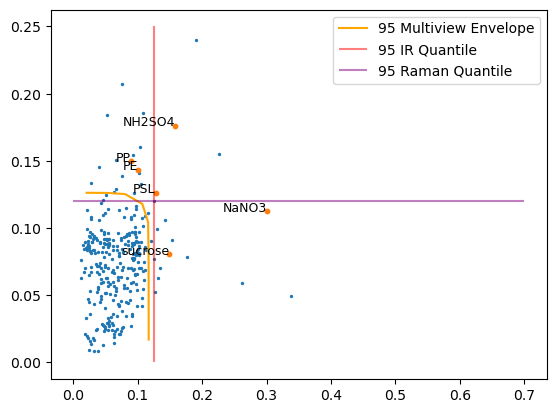

In [193]:
env_data_95 = pd.DataFrame(np.array(env_list[5][0]).T)
env_data_95.columns = ['x - 95','y - 95']

plt.scatter(cal_smx_arr[0],
            cal_smx_arr[1], s=2)

plt.scatter(score_example[0],
            score_example[1], s=10)

for i in range(6):
    plt.text(score_example[0][0, i], 
             score_example[1][0, i], label_table.iloc[i,1], fontsize=9, ha='right')
    
    
_ = plt.plot(env_data_95['x - 95'],
             env_data_95['y - 95'], color='orange', label='95 Multiview Envelope')

_ = plt.vlines(x= q_ir,
                ymin=0,
                ymax=.25,
                colors='r',
                alpha=.5,
                linestyles='solid',
                label='95 IR Quantile')

_ = plt.hlines(y= q_raman,
                xmin=0,
                xmax=.7,
                colors='purple',
                alpha=.5,
                linestyles='solid',
                label='95 Raman Quantile')

_ = plt.legend()

In [513]:
q_raman = q_raman_list[5][0]
q_ir = q_ir_list[5][0]

In [515]:
pred_sets_95_ex = pd.DataFrame({'IR':ps_ir_list[5],
              'Raman':ps_raman_list[5],
              'MVCP':ps_list[5]})
pred_sets_95_ex#.to_csv('results/pred_sets_95_fig_2a_id_217.csv')
pred_sets_95_ex

,IR,Raman,MVCP
0,"[NH2SO4, NaNO3, PE, PP, PSL, sucrose]","[PE, PP]","[PE, PP, sucrose]"


In [518]:
quantile_95 = pd.DataFrame({'95 HQI Quantile (IR)':[1-q_ir],
              '95 HQI Quantile (Raman)':[1-q_raman]})
#quantile_95.to_csv('results/quantile_95_data_fig_2a.csv')
quantile_95

,95 HQI Quantile (IR),95 HQI Quantile (Raman)
0,0.874212,0.854884


In [125]:
alpha = .1
beta, q_array, U = calibrate_beta_mv(alpha, quant_smx_list, quant_labels)
#U = np.array([u/np.linalg.norm(u) for u in U])
n = rest_smx_list[0].shape[0]
t = np.max([project_u_mv(rest_smx_list, U[th,:])[0][np.arange(n),rest_labels]/q for th, q in enumerate(q_array)], 0)


cal_x = smx_all_IR[np.arange(label_ir.shape[0]),label_ir]
cal_y = smx_all_Raman[np.arange(label_ir.shape[0]),label_ir]

#plt.scatter(cal_x[cal_x<.2],
#            cal_y[cal_x<.2], 
#            label='calibration set')

plt.scatter(quant_smx_list[0][np.arange(quant_labels.shape[0]),quant_labels],
            quant_smx_list[1][np.arange(quant_labels.shape[0]),quant_labels], 
            label='calibration set')

#plt.scatter(smx_all_IR_rest.min(1),
#            smx_all_Raman_rest.min(1))

#plt.scatter(U[:,0],
#            U[:,1])

#plt.scatter(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t,
#            rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t, 
#            label='quantile region')

idx_quant_reg = np.argsort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_x = np.sort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_y = (rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t)[idx_quant_reg]

plt.plot(quant_reg_x,
         quant_reg_y, 
         label='quantile region',
         c='orange',
         linewidth=3.0
     )

plt.xlabel("IR 1-HQI")
plt.ylabel("Raman 1-HQI")
plt.xlim(0.0,.16)
plt.ylim(0.0,.16)

plt.legend()

NameError: name 'quant_smx_list' is not defined

# C